In [1]:
import numpy as np
import pandas
import xarray as xr
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA
import rasterio

PATH_LABEL = "/home/hkerino/Documents/nextoso-dataset/data/10m/labels"
PATH_PLOT_S2 = "/home/hkerino/Documents/nextoso-dataset/data/10m/plots/S2_one_timestep"
PATH_tessera_npy = "/home/hkerino/Documents/nextoso-dataset/tessera_data"
PATH_alpha_earth_npy = "/home/hkerino/Documents/nextoso-dataset/alpha-earth_data"
path_oso_class = (
    "/home/hkerino/Documents/nextoso-dataset/data/auxiliary/OSO/oso_classes.csv"
)

## Functions

In [2]:
OSO_COLORS = {
    1: (255, 0, 255),  # Urbain dense
    2: (255, 85, 255),  # Urbain diffus
    3: (255, 170, 255),  # Zones industrielles et commerciales
    4: (0, 255, 255),  # Routes
    5: (255, 255, 0),  # Colza
    6: (208, 255, 0),  # Céréales à paille
    7: (161, 214, 0),  # Protéagineux
    8: (255, 170, 68),  # Soja
    9: (214, 214, 0),  # Tournesol
    10: (255, 85, 0),  # Maïs
    11: (197, 255, 255),  # Riz
    12: (170, 170, 97),  # Tubercules / Racines
    13: (170, 170, 0),  # Prairies
    14: (170, 170, 255),  # Vergers
    15: (85, 0, 0),  # Vignes
    16: (0, 156, 0),  # Forêts de feuillus
    17: (0, 50, 0),  # Forêts de conifères
    18: (170, 255, 0),  # Pelouse
    19: (85, 170, 127),  # Landes
    20: (255, 0, 0),  # Surfaces minérales
    21: (255, 184, 2),  # Plages et Dunes
    22: (190, 190, 190),  # Glaciers et neiges éternelles
    23: (0, 0, 255),  # Eau
    24: (68, 121, 200),  # Serres
}
# Ajouter une couleur pour la classe 0 ('nan')
OSO_COLORS[0] = (128, 128, 128)  # Gris pour 'nan'
# Normaliser les couleurs (diviser par 255)
normalized_colors = [
    (r / 255, g / 255, b / 255)
    for r, g, b in [OSO_COLORS[i] for i in sorted(OSO_COLORS.keys())]
]
cmap = ListedColormap(normalized_colors)
name_classes = pandas.read_csv(path_oso_class).get("name_class")


def plot_label(label):
    fig, ax = plt.subplots()
    im = ax.imshow(label, cmap=cmap, vmin=0, vmax=24)
    cbar = fig.colorbar(im, ticks=np.arange(0, 25))
    cbar.ax.set_yticklabels([name_classes[i] for i in range(25)])
    ax.axis("off")


def plot_emb(id, figsize=(20, 5)):
    id = f"{id:04d}"
    # label
    label = xr.open_dataset(f"{PATH_LABEL}/label_{id}.nc")["max_class_1"].data

    # s2 plot
    with rasterio.open(f"{PATH_PLOT_S2}/s2_{id}.tif") as src:
        b1 = src.read(1)
        b2 = src.read(2)
        b3 = src.read(3)

    img_s2 = np.dstack((b1, b2, b3))

    # Alpha earth
    alpha_earth_npy = np.load(f"{PATH_alpha_earth_npy}/alpha-earth_{id}.npy")
    X = alpha_earth_npy.reshape(64, -1).T
    pca = PCA(n_components=3)
    rgb = pca.fit_transform(X)
    rgb = rgb.reshape(128, 128, 3)
    img_alpha_earth = (rgb - rgb.min()) / (rgb.max() - rgb.min())

    # npy
    data_tessera_npy = np.load(f"{PATH_tessera_npy}/tessera_{id}.npy")
    X = data_tessera_npy.reshape(128, -1).T
    pca = PCA(n_components=3)
    rgb = pca.fit_transform(X)
    rgb = rgb.reshape(128, 128, 3)
    img_tessera = (rgb - rgb.min()) / (rgb.max() - rgb.min())

    # plot
    fig, axs = plt.subplots(1, 4, figsize=figsize)

    axs[0].imshow(img_s2)
    axs[0].set_title("S2 Image")
    axs[0].axis("off")

    axs[1].imshow(img_alpha_earth)
    axs[1].set_title("Alpha Earth PCA")
    axs[1].axis("off")

    axs[2].imshow(img_tessera)
    axs[2].set_title("Tessera PCA")
    axs[2].axis("off")

    im = axs[3].imshow(label, cmap=cmap, vmin=0, vmax=24)
    cbar = fig.colorbar(im, ticks=np.arange(0, 25))
    cbar.ax.set_yticklabels([name_classes[i] for i in range(25)])
    axs[3].set_title("Label")
    axs[3].axis("off")
    plt.tight_layout()
    plt.show()

## Plot

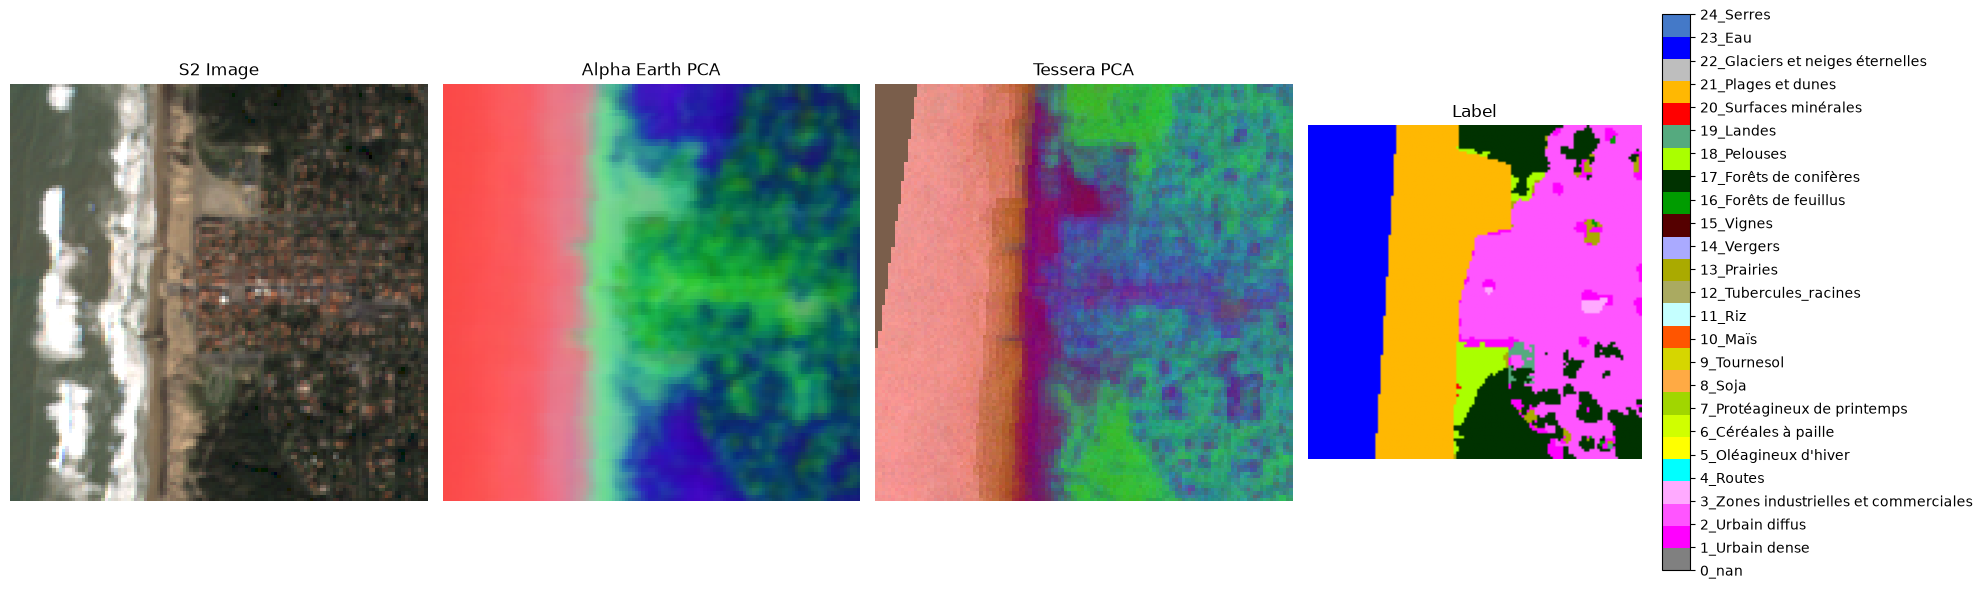

In [3]:
plot_emb(27, figsize=(20, 6))

In [6]:
from embedding import dataset_embedding

d = dataset_embedding.embedding_dataset(
    model="tessera", fold=[1, 2, 3, 4, 5], mask=True
)

In [7]:
d.__len__()

3598

(np.float64(-0.5), np.float64(127.5), np.float64(127.5), np.float64(-0.5))

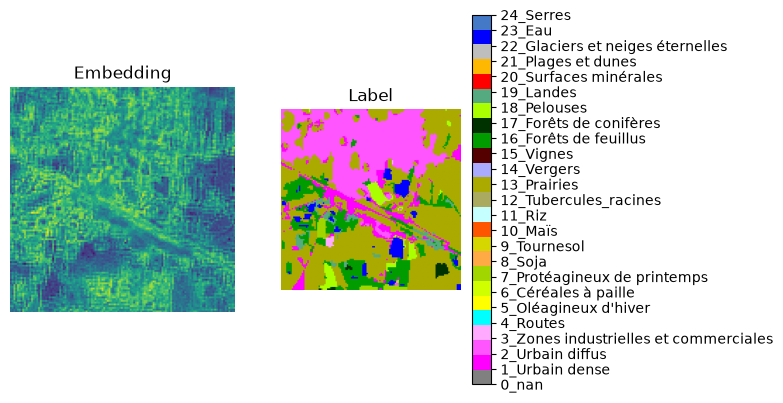

In [11]:
emb, label = d.__getitem__(29)

fig, axs = plt.subplots(1, 2)

axs[0].imshow(emb[0, :, :])
axs[0].set_title("Embedding")
axs[0].axis("off")

im = axs[1].imshow(label, cmap=cmap, vmin=0, vmax=24)
cbar = fig.colorbar(im, ticks=np.arange(0, 25))
cbar.ax.set_yticklabels([name_classes[i] for i in range(25)])
axs[1].set_title("Label")
axs[1].axis("off")

## Plot PASTIS

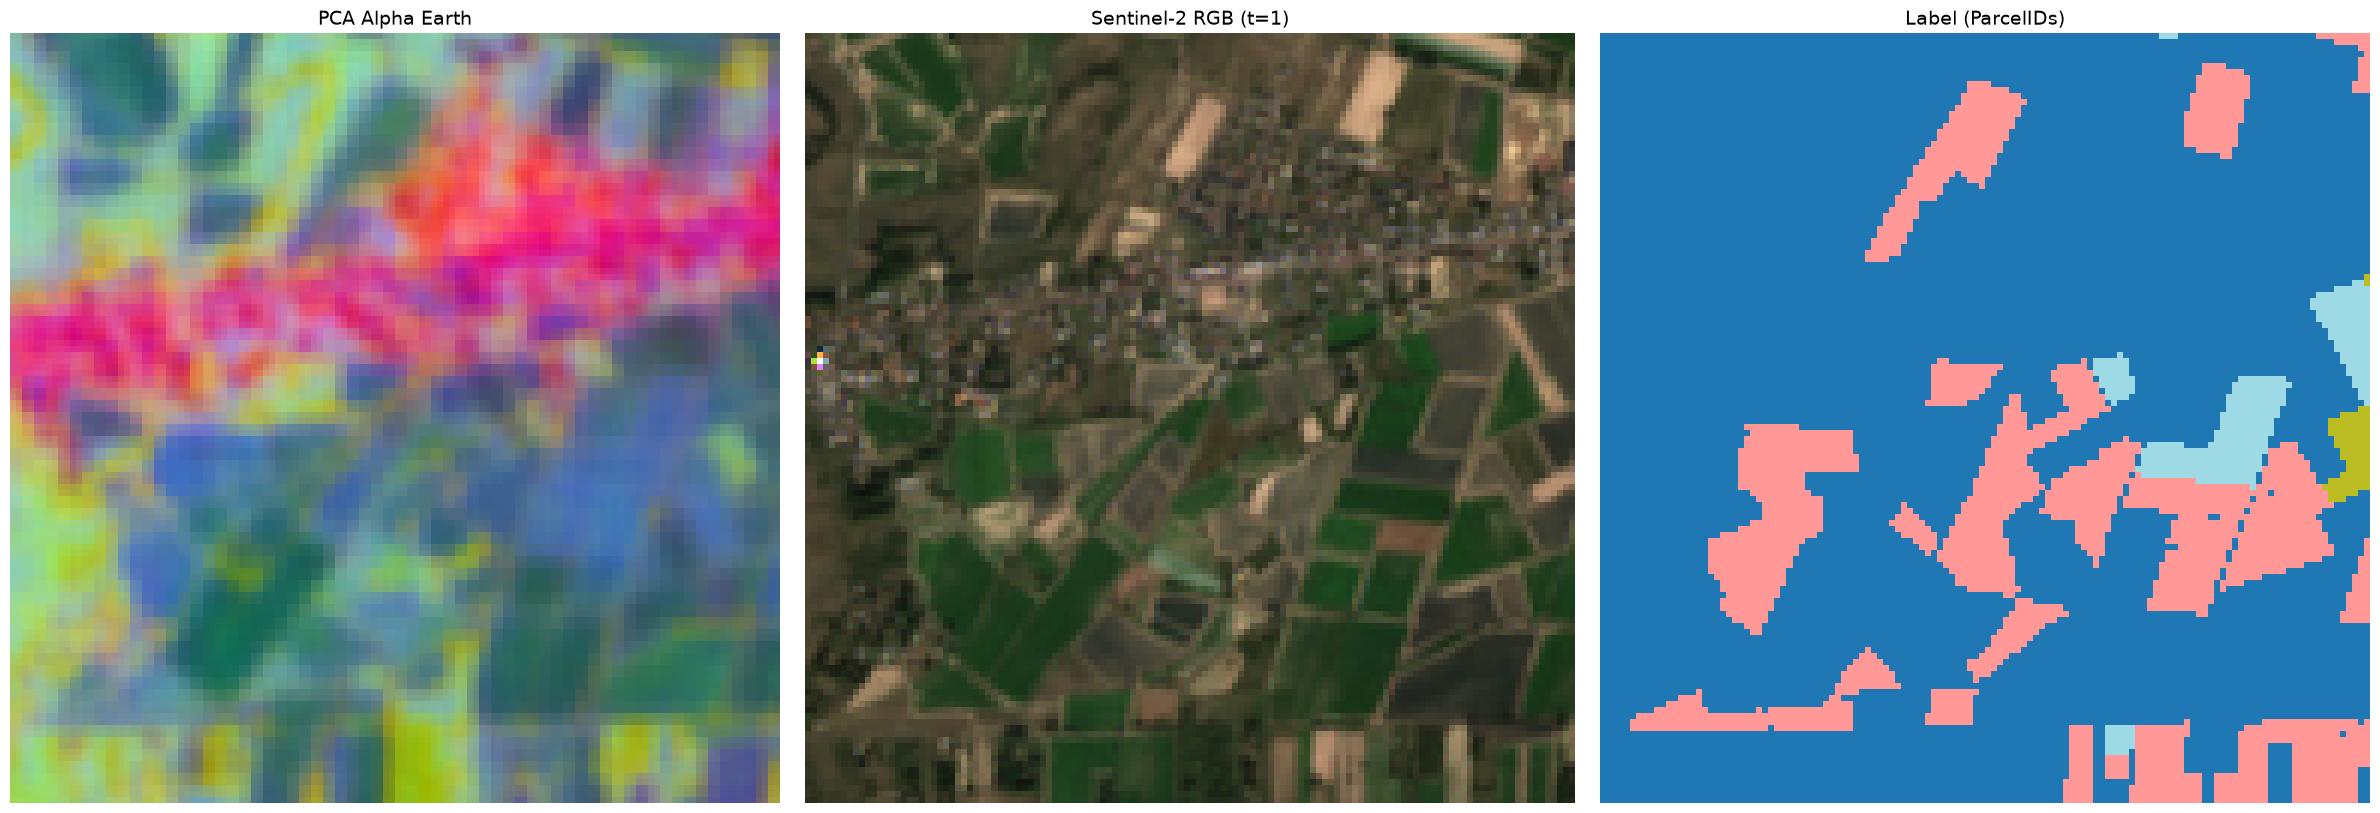

In [23]:
# Charger le label et S2
PATH_PASTIS = "/home/hkerino/Documents/PASTIS"
id = "10004"
ae = np.load(f"{PATH_PASTIS}/ALPHA_EARTH_npy/alpha_earth_{id}.npy")
label = np.load(f"{PATH_PASTIS}/ANNOTATIONS/ParcelIDs_{id}.npy")
s2 = np.load(f"{PATH_PASTIS}/DATA_S2/S2_{id}.npy")

# pca
X = ae.reshape(64, -1).T
pca = PCA(n_components=3)
rgb = pca.fit_transform(X)
rgb = rgb.reshape(128, 128, 3)
img_alpha_earth = (rgb - rgb.min()) / (rgb.max() - rgb.min())

# Sélectionner un timestep et extraire les 3 bandes RGB
# S2 shape: (T, C, H, W) - sélectionner t=0 et bandes RGB [2, 1, 0] (Red, Green, Blue)
t = 1
s2_rgb = s2[t, [2, 1, 0], :, :].transpose(1, 2, 0)  # (H, W, 3)

# Normaliser S2 entre 0 et 1
s2_rgb = np.clip(s2_rgb / 3000, 0, 1)  # Sentinel-2 a des valeurs jusqu'à ~3000


# Plotter PCA RGB, S2 RGB et label
fig, axes = plt.subplots(1, 3, figsize=(24, 8))

axes[0].imshow(img_alpha_earth)
axes[0].set_title("PCA Alpha Earth", fontsize=14)
axes[0].axis("off")

axes[1].imshow(s2_rgb)
axes[1].set_title(f"Sentinel-2 RGB (t={t})", fontsize=14)
axes[1].axis("off")

axes[2].imshow(label, cmap="tab20")
axes[2].set_title("Label (ParcelIDs)", fontsize=14)
axes[2].axis("off")

plt.tight_layout()
plt.show()